
# AirDraw AI — Hand Gesture Detection with YOLOv8

**CSCI1409 Deep Learning — Bonus Project**

This project trains a YOLOv8n object detector to recognize four hand gestures:

- Fist
- Open Palm
- Point
- Thumbs Up

We fine-tune a pretrained YOLOv8n model and compare two learning rates.

**Experiment 1:** Learning Rate = 0.00125

**Experiment 2:** Learning Rate = 0.000625

The best model is selected using validation results and evaluated on a separate test dataset.

The project also includes a gesture-controlled virtual drawing application.


In [3]:

%pip install ultralytics==8.4.215 roboflow pyyaml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 39.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 119.8 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [4]:

from roboflow import Roboflow
from google.colab import userdata
from pathlib import Path

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))

project = rf.workspace("akerke-zhumabekova").project("hand-gesture-detection-base-hehmh")
version = project.version(1)

dataset = version.download("yolov8")
data_path = Path(dataset.location)

print("Dataset:", data_path)
print("Config:", data_path / "data.yaml")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Hand-Gesture-Detection-Base-1 in yolov8:: 100%|██████████| 3324/3324 [00:01<00:00, 2053.37it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dataset: /content/Hand-Gesture-Detection-Base-1
Config: /content/Hand-Gesture-Detection-Base-1/data.yaml


In [5]:

import yaml

with open(data_path / "data.yaml", "r") as f:
    config = yaml.safe_load(f)

print("Classes:", config["names"])
print("Number of classes:", config["nc"])

for split in ["train", "valid", "test"]:
    images = list((data_path / split / "images").glob("*"))
    labels = list((data_path / split / "labels").glob("*.txt"))

    print(f"{split}: {len(images)} images, {len(labels)} label files")

Classes: ['fist', 'open-palm', 'point', 'thumbs-up']
Number of classes: 4
train: 1162 images, 1162 label files
valid: 332 images, 332 label files
test: 166 images, 166 label files


In [6]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4



## 5. Baseline Training

We fine-tune the pretrained YOLOv8n model for 20 epochs.

The baseline uses the AdamW optimizer with a learning rate of 0.00125.

The model is trained on the training split and evaluated on the validation split.


In [7]:

from ultralytics import YOLO

model = YOLO("yolov8n.pt")

baseline = model.train(
    data=str((data_path / "data.yaml").resolve()),
    epochs=20,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.00125,
    momentum=0.9,
    seed=42,
    workers=0,
    device=0,
    plots=True,
    project="AirDraw_Results",
    name="baseline"
)

New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Hand-Gesture-Detection-Base-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.00125, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, mo


## 6. Experiment 2 — Lower Learning Rate

**Hypothesis:** Reducing the learning rate from 0.00125 to 0.000625 may improve YOLOv8n detection performance.

We keep the same dataset, pretrained weights, optimizer, batch size, image size, epochs, and random seed.

Only the learning rate is changed.


In [8]:

from ultralytics import YOLO

model2 = YOLO("yolov8n.pt")

experiment2 = model2.train(
    data=str((data_path / "data.yaml").resolve()),
    epochs=20,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.000625,
    momentum=0.9,
    seed=42,
    workers=0,
    device=0,
    plots=True,
    project="AirDraw_Results",
    name="lower_lr"
)


New https://pypi.org/project/ultralytics/8.4.216 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Hand-Gesture-Detection-Base-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.000625, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, m

In [10]:

from ultralytics import YOLO
import pandas as pd

baseline_model = YOLO(
    "runs/detect/AirDraw_Results/baseline/weights/best.pt"
)

lower_model = YOLO(
    "runs/detect/AirDraw_Results/lower_lr/weights/best.pt"
)

baseline_val = baseline_model.val(
    data=str((data_path / "data.yaml").resolve()),
    split="val",
    imgsz=640,
    device=0,
    plots=False
)

lower_val = lower_model.val(
    data=str((data_path / "data.yaml").resolve()),
    split="val",
    imgsz=640,
    device=0,
    plots=False
)

comparison = pd.DataFrame({
    "Metric": ["Precision", "Recall", "mAP50", "mAP50-95"],
    "Baseline": [
        baseline_val.box.mp,
        baseline_val.box.mr,
        baseline_val.box.map50,
        baseline_val.box.map
    ],
    "Lower LR": [
        lower_val.box.mp,
        lower_val.box.mr,
        lower_val.box.map50,
        lower_val.box.map
    ]
})

print(comparison.round(4))


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 767.3±302.9 MB/s, size: 22.2 KB)
val: Scanning /content/Hand-Gesture-Detection-Base-1/valid/labels.cache... 332 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 332/332 116.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 9.0it/s 2.3s
                   all        332        314      0.789      0.676      0.758      0.526
                  fist         89         89      0.748       0.73      0.831      0.592
             open-palm         99        100      0.723       0.64      0.712      0.426
                 point         38         38      0.953          1      0.995      0.777
             thumbs-up         87         87      0.733      0.333      0.495      0.307
Speed: 0.6ms preprocess, 

In [13]:

from ultralytics.cfg import DEFAULT_CFG

print("Default confidence:", DEFAULT_CFG.conf)
print("Default NMS IoU:", DEFAULT_CFG.iou)

Default confidence: None
Default NMS IoU: None


In [14]:

from ultralytics import YOLO

best_model = YOLO(
    "runs/detect/AirDraw_Results/lower_lr/weights/best.pt"
)

test_results = best_model.val(
    data=str((data_path / "data.yaml").resolve()),
    split="test",
    imgsz=640,
    conf=0.001,
    iou=0.7,
    device=0,
    plots=True,
    project="AirDraw_Results",
    name="final_test"
)

print("Precision:", round(test_results.box.mp, 4))
print("Recall:", round(test_results.box.mr, 4))
print("mAP50:", round(test_results.box.map50, 4))
print("mAP50-95:", round(test_results.box.map, 4))

print("Confidence threshold:", 0.001)
print("NMS IoU threshold:", 0.7)


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1384.2±454.1 MB/s, size: 27.4 KB)
val: Scanning /content/Hand-Gesture-Detection-Base-1/test/labels.cache... 166 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 166/166 41.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 4.5it/s 2.4s
                   all        166        156      0.863      0.698      0.799      0.589
                  fist         59         60      0.875      0.816      0.883      0.673
             open-palm         38         38      0.876      0.526      0.753      0.436
                 point         18         18      0.861          1      0.995      0.848
             thumbs-up         40         40      0.839       0.45      0.565      0.398
Speed: 1.2ms preprocess, 4

In [17]:

from pathlib import Path
from google.colab import files
import shutil

source = Path("/content/runs/detect/AirDraw_Results")

assert source.exists(), "Training results not found"

archive = shutil.make_archive(
    "/content/AirDraw_AI_Results",
    "zip",
    root_dir=source.parent,
    base_dir=source.name
)

print("Archive created:", archive)

for name in ["baseline", "lower_lr"]:
    path = source / name / "weights" / "best.pt"
    print(name, "best.pt:", path.exists())

files.download(archive)


Archive created: /content/AirDraw_AI_Results.zip
baseline best.pt: True
lower_lr best.pt: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

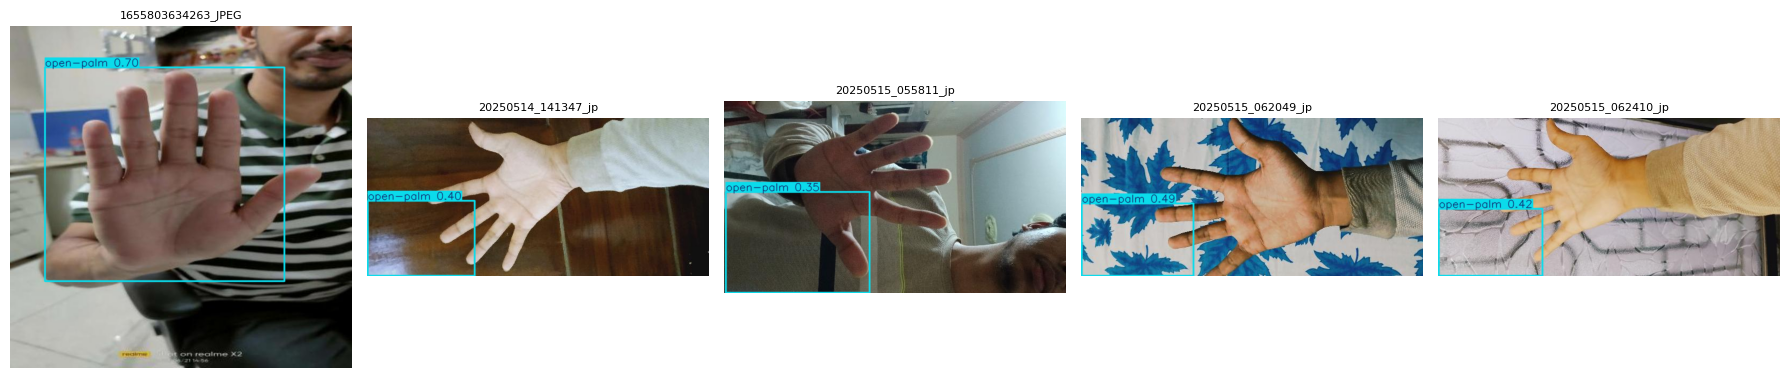

In [18]:

from pathlib import Path
import matplotlib.pyplot as plt

test_images = sorted(
    list((data_path / "test" / "images").glob("*.jpg")) +
    list((data_path / "test" / "images").glob("*.png"))
)

predictions = best_model.predict(
    source=[str(p) for p in test_images],
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)

detected = [r for r in predictions if len(r.boxes) > 0]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, result in zip(axes, detected[:5]):
    ax.imshow(result.plot()[:, :, ::-1])
    ax.axis("off")
    ax.set_title(Path(result.path).name[:18], fontsize=8)

plt.tight_layout()
plt.show()

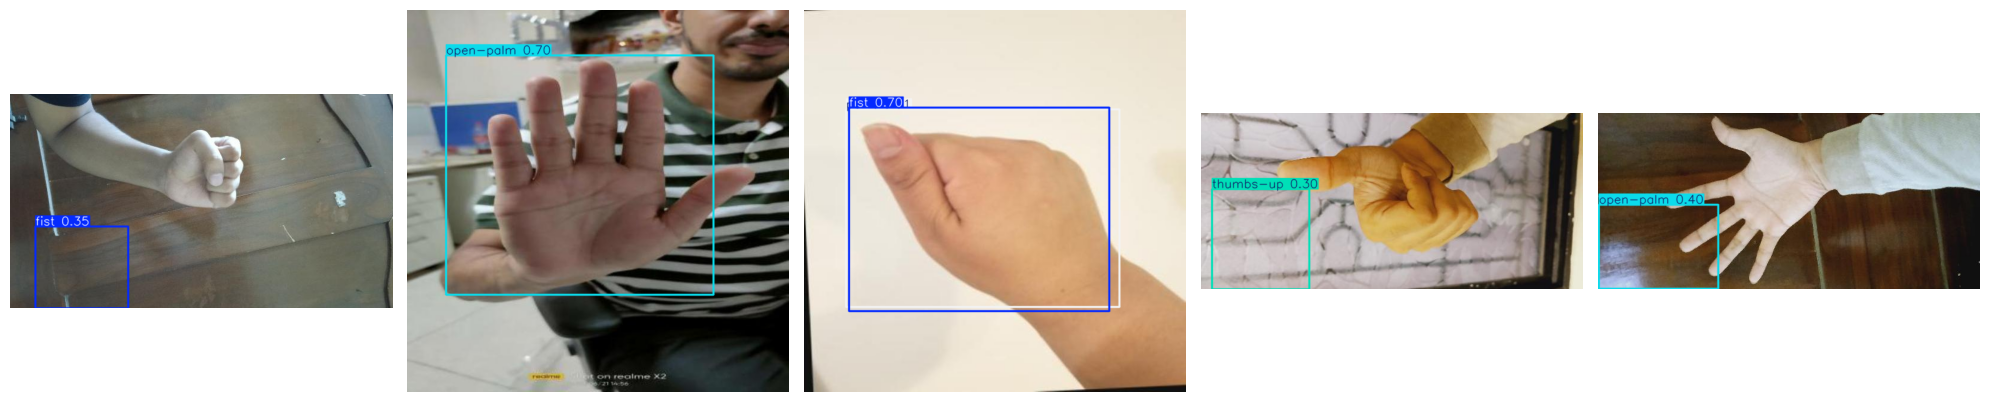

In [19]:

import matplotlib.pyplot as plt

selected = []

for class_id in range(4):
    for result in predictions:
        if class_id in result.boxes.cls.int().tolist():
            selected.append(result)
            break

# Add a fifth prediction
for result in predictions:
    if len(result.boxes) > 0 and result.path not in [r.path for r in selected]:
        selected.append(result)
        break

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, result in zip(axes, selected):
    ax.imshow(result.plot()[:, :, ::-1])
    ax.axis("off")

plt.tight_layout()
plt.show()


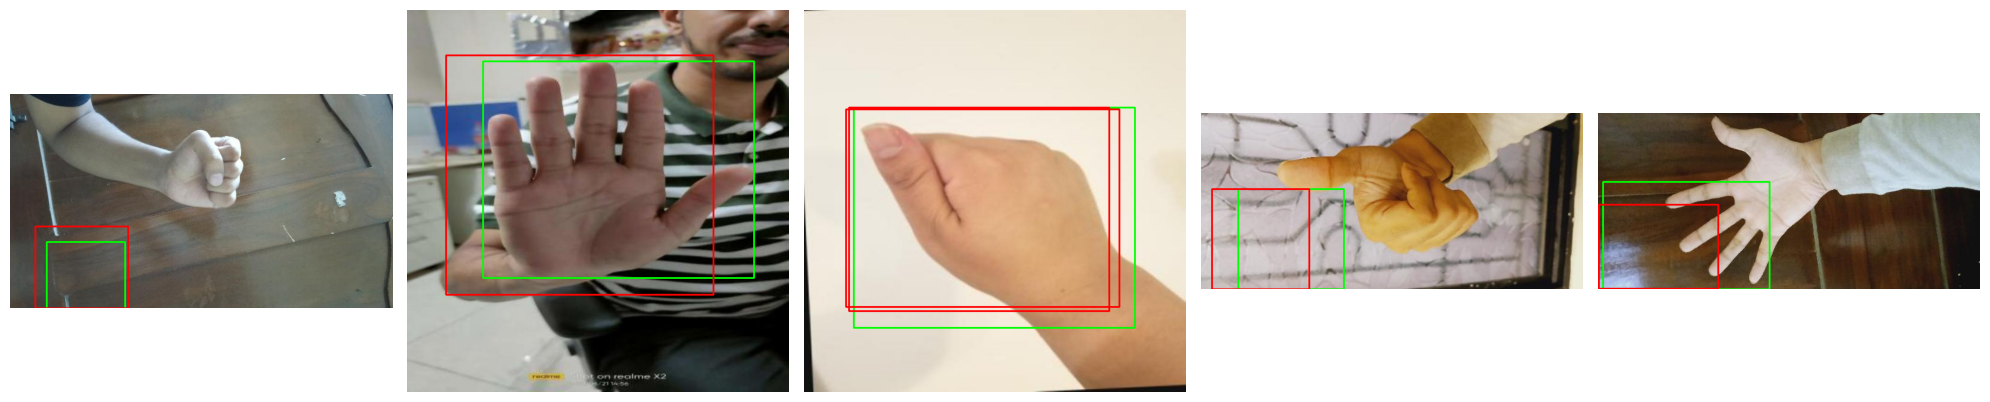

In [20]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, result in zip(axes, selected):
    image = cv2.imread(result.path)
    h, w = image.shape[:2]

    label_path = data_path / "test" / "labels" / (
        Path(result.path).stem + ".txt"
    )

    # Ground Truth — green
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            cls, x, y, bw, bh = map(float, line.split())

            x1 = int((x - bw / 2) * w)
            y1 = int((y - bh / 2) * h)
            x2 = int((x + bw / 2) * w)
            y2 = int((y + bh / 2) * h)

            cv2.rectangle(image, (x1, y1), (x2, y2),
                          (0, 255, 0), 2)

    # Prediction — red
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        cv2.rectangle(image, (x1, y1), (x2, y2),
                      (0, 0, 255), 2)

    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.axis("off")

plt.tight_layout()
plt.savefig("failure_analysis.png", dpi=150)
plt.show()


## Failure Analysis

We compared YOLO predictions with ground-truth bounding boxes on the test dataset.

Green boxes represent ground-truth annotations, while red boxes represent model predictions.

### Failure 1 — Incorrect Fist Localization

In the first image, the predicted bounding box is located below the actual fist.

The ground-truth annotation is also shifted away from the hand.

This suggests that inaccurate annotations may affect the model's localization performance.

### Failure 2 — Incorrect Thumbs-Up Localization

In the fourth image, the predicted bounding box covers part of the background instead of the hand.

The ground-truth box is also incorrectly positioned.

A possible cause is poor bounding-box annotation quality.

### Failure 3 — Inaccurate Open-Palm Bounding Box

In the fifth image, the predicted bounding box does not cover the entire open palm.

The model detects the gesture but estimates its location inaccurately.

### Suggested Improvement

A practical next step is to review and correct the inaccurate bounding-box annotations.

After improving the annotations, we could retrain the model and check whether its localization performance improves.

### Limitations

The model performs well on some gestures, especially the point gesture, but it still has problems with inaccurate bounding boxes.

The current results are based on a relatively small test dataset and may not fully represent real-world webcam performance.


In [23]:

from google.colab import files

files.download(
    "/content/runs/detect/AirDraw_Results/lower_lr/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>